# Faster R-CNN and YOLO11s: inference views with NMS threshold, flip and multi-scale TTA, WBF and a SAHI gate (pipeline, tuned)

## Overview

Parent run: `faster-rcnn-giou` (T3, run `dmnk1304/faster-rcnn-giou`): torchvision `fasterrcnn_resnet50_fpn_v2`, COCO weights, 1280 px, anchor sizes 16–256, GIoU box loss. This notebook trains nothing and uses no legacy notebook code. It loads the `best.pt` of three finished runs (kernel sources) and changes only how their detections are produced.

**What changes.** One thing: the inference procedure. Each model predicts the same frames through several inference views, and the detections of the views are fused with class-wise weighted boxes fusion (WBF, Solovyev et al., arXiv:1910.13302). The three models (the `SOURCE_KERNELS` of the Config) are:

| Label | Run | Family | Role | Full-val mAP@500 | AP_small | ms/img |
|---|---|---|---|---|---|---|
| T1 | `draklowell/faster-rcnn-small-anchors` | two_stage | plain reference | 0.2312 | 0.1212 | 179.0 |
| T3 | `dmnk1304/faster-rcnn-giou` | two_stage | Faster R-CNN with all views | 0.2371 | 0.1312 | 241.8 |
| T7 | `dmnk1304/yolo11s-1280-p2` | anchor_free | YOLO with all views | 0.2165 | 0.1146 | 45.0 |

Metrics: full val, `EXPERIMENTS.md`. They are not an input of this notebook. Each model's `result.json` is read at run time, and its recorded `mAP` is compared with the `mAP` of the plain view recomputed here.

| Item | Plain view (the parent run) | This run |
|---|---|---|
| Second-stage NMS threshold `box_nms_thresh` (Faster R-CNN) | 0.5 | 0.5, 0.6 or 0.7, chosen per model on the quick-val frames from `NMS_THRESHOLDS` |
| Horizontal flip | no | extra view of the same frame, boxes mirrored back |
| Input scale (long side) | 1280 | extra views at the long sides of `SCALE_SIZES` (1600, 1920) |
| Fusion of the views | not applicable | class-wise WBF, IoU threshold chosen on quick-val frames from `WBF_IOU_THRESHOLD_GRID` |
| SAHI slicing | no | gated on the quick-val frames (see below) |
| Model weights | trained in the parent run | none trained; the `best.pt` files are loaded |

Config constants of the change: `SOURCE_KERNELS`, `NMS_THRESHOLDS`, `SCALE_SIZES`, `WBF_IOU_THRESHOLD_GRID`, `SAHI_SLICE_SIZE`, `SAHI_OVERLAP_RATIO`, `SAHI_GATE_AP_SMALL_GAIN`. There is no forced side change. `PARENT_RUN` names T3; T1 and T7 are listed in `result.json` under `source_kernels`. Soft-NMS is not run: the 500-detection cap is reached on almost every frame (`SCOPE.md` F26), and WBF takes its place.

**Why** (`SCOPE.md` findings F9, F25, F26, F39, F42, F58, F62, numbers in `EXPERIMENTS.md`):
- `box_nms_thresh` 0.5 → 0.6 raised the final recall at IoU 0.7 in the earlier Faster R-CNN runs: T2 0.5750 → 0.5986 (small objects 0.364 → 0.395) and T3 0.5845 → 0.6061 (small 0.361 → 0.388), with the detections per frame rising from 457.9 to 488.1 for T3 (F25, F39). The effect on mAP was not measured. This run measures it.
- Small objects are the weakest bucket: 21,910 of 114,132 val boxes are below 32² px, and the recall at IoU 0.5 for them is 0.5691 in T7 (F42). Views at a larger input scale give a small object more pixels.
- The test frames differ in resolution from the labelled ones: all test clips are at most 1920 px wide, 8 test clips (680×382 and 960×540) are smaller than any labelled clip, and no test clip is 2688 px or wider, while 13 train and 2 val clips are (F9, EDA notebook `notebooks/eda.ipynb`, §5). The scale-robustness table of this notebook runs the same models on val frames downscaled to these two widths.
- Fusion of different families gained more than fusion of near-duplicate runs: T3+T7 0.2654 against 0.2608 for four fused Faster R-CNN runs (F58, F62). Every inference view is saved as its own `val_predictions.json` / `submission.csv` pair so that the later ensemble notebook can fuse the views as additional members. A view that does not improve its own model can still help the fusion, so every view is saved, whichever test it passed.

**Expectation.** The effect of the NMS threshold on mAP, and the effect of flip and scale views, are not predicted. The test images are at most 1920 px wide, so the scale views are expected to cover most of what SAHI slicing would add for small objects, at a fraction of the compute. The decision rule of `SCOPE.md` §3.10 applies to any claim that a row is better than its model's plain row: full-val mAP@500 at least 0.01 higher **and** a per-clip AP delta of the same sign on at least 5 of the 7 val clips; both are in `inference_ablation.csv`.

**Views.** A view is a triple (input long side, flipped or not, NMS threshold). The view at long side 1280, no flip and NMS threshold 0.5 is the plain view, which is how the parent run predicted. The view plan, in the order it is computed (a view is skipped if it would not fit the time guard):
1. plain views of T3, T7 and T1;
2. T3 at its selected NMS threshold (no new view if the selected threshold is 0.5);
3. flip views at 1280 of T7 and T3 (T3 at its selected threshold);
4. scale views at 1600 and 1920 of T7 and then of T3 (T3 at its selected threshold).

**Ablation rows** (`inference_ablation.csv`, full val, mAP@500, AP_small, ms/img, AP per clip and the mean AP over the clips without the 4K clip `uav0000268_05773_v`): plain of T1, T3, T7 → T3 at the selected NMS threshold → flip views fused → scale views fused → all views fused, for T3 and for T7 → the cross-family fusion of all views of T3 and T7 (this row also gives `val_predictions.json`, `submission.csv` and `result.json`) → SAHI rows, only if the SAHI full run took place.

**Selection and validity.**
- The NMS threshold of each Faster R-CNN model, the WBF IoU threshold and the SAHI gate are decided on the 571 quick-val frames only (every 5th `val/` frame). Metrics are reported on all 2,846 val frames. The members' checkpoints were also selected on the quick-val frames, so the full-val score is slightly optimistic.
- Nothing is fitted on training data, and no weights are learned. The `best.pt` files come from runs that trained on `train/` clips only, so the fused val score is a hold-out score.
- The WBF IoU threshold is chosen once, on the fusion of all T3 views, and used for every fused row. The WBF `skip_box_thr` is `CONF_THRESHOLD`. All view weights are equal.
- Test detections are produced by the same views, the same selected thresholds and the same fusion as the val detections. Nothing is tuned on test.

**Comparison with the legacy parent.** The parents T1 and T3 ran under the current protocol, so no protocol difference enters the comparison of this run with them. T7's own parent is the legacy run `dmnk1304/yolo-3-1280`; the legacy protocol differs from the current one as follows (from the † note in `EXPERIMENTS.md`): no ignore fill (ignored areas trained as background); GT inside ignore regions not dropped; checkpoint chosen by Ultralytics fitness on all val frames, no quick-val COCOeval; no `seed_everything`, no `MAX_TRAIN_HOURS` guard; pycocotools installed with pip; result file without versions, speed protocol and other core keys; legacy output names, `last.pt` and `runs/` saved; no `submission_check.json`; submission coordinates rounded to 1 decimal. This notebook compares the views of T7 only with its own plain view, not with `yolo-3-1280`.

**SAHI gate.** Slicing aided hyper inference (SAHI, Akyon et al., arXiv:2202.06934) cuts the frame into overlapping slices, runs the detector on every slice and on the full frame, and merges the detections. The `sahi` package is not installed (it is not in the `kaggle` dependency group); the slicing and the merge are implemented in this notebook after the paper: slices of `SAHI_SLICE_SIZE` = 640 px with an overlap ratio of `SAHI_OVERLAP_RATIO` = 0.2 plus the full frame, merged with class-wise NMS at IoU `SAHI_MERGE_IOU` (the SAHI package merges with an intersection-over-smaller match metric by default; this is the nearest option that needs no extra package). The gate runs plain and sliced prediction of the model `SAHI_MODEL_LABEL` on the quick-val frames and writes `sahi_gate.csv`. The full-val and test SAHI view is computed only if the quick-val AP_small rises by at least `SAHI_GATE_AP_SMALL_GAIN` = 0.005 **and** the projected time fits the guard. The model is T7, because slicing multiplies the number of forward passes by the number of slices and T7 is the fastest model.

**Budget and the time guard.** No epochs are trained. `MAX_TRAIN_HOURS` = 6 bounds the whole run: before each view after the first two plain ones, the projected time of the view (measured wall time per frame of the model's plain view times pixel ratio times `VIEW_OVERHEAD_FACTOR` times val and test frames) plus `EVALUATION_RESERVE_HOURS` for the COCOeval and fusion work of the ablation must fit into the hours left; otherwise the view is skipped and listed in `result.json` under `skipped_views`. Rows that need a skipped view are left out and listed under `skipped_rows`. Speeds of different Kaggle sessions are not comparable (`SCOPE.md` F34): read `ms_per_image` together with the torch build in `versions`.

**Two GPUs.** The run uses both GPUs of the Kaggle GPU T4 x2 machine (accelerator `NvidiaTeslaT4`, the one `uv run push-notebook` requests) to cut the wall time. Each model is loaded once per GPU, and every batch of frames (or, in the SAHI view, the slices of one frame) is split into two contiguous halves that the two replicas predict in parallel, with the same weights and settings. The per-GPU batch of T7 shrinks with the input size (`YOLO_BATCH_BY_SIZE`): the previous version of this run used batch 16 on one GPU at every size and ran out of GPU memory in the YOLO11 attention block at 1600 px.

**Extra outputs of this run.** Besides the standard outputs, `per_clip_ap.csv` and `size_breakdown.csv` (both for the cross-family fusion):
- `history.csv`: the quick-val trace (NMS thresholds, SAHI gate, WBF IoU thresholds), one row per trial, with quick-val mAP and AP50; there are no training epochs;
- `inference_ablation.csv` and `fig_inference_ablation.png` (+ `.csv`);
- `sahi_gate.csv`: plain and sliced prediction on the quick-val frames;
- `scale_robustness.csv`: T3 and T7 on the quick-val frames at native size and downscaled to widths 960 and 680 (the test widths of the small clips);
- `view_<label>_<view>_val_predictions.json` and `view_<label>_<view>_submission.csv` for every computed view (`<view>` encodes long side, `flip`, `nms<threshold>`, `sahi<slice>`), COCO results format and submission format, top 500 per frame.

`best.pt` and the training curves do not apply, because nothing is trained.

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

**How the protocol applies to an inference run.**
- The split, the 56 training clips and the ignore handling belong to the training of the three source runs. This notebook only checks the frame counts. It does not fill ignore regions, because it trains nothing. Evaluation uses the same `val/annotations_coco.json` with `iscrowd=1`.
- There are no epochs. The selections (NMS threshold, WBF IoU threshold, SAHI gate) use the quick-val frames, and `MAX_TRAIN_HOURS` bounds the whole run. Every view predicts in fp32 with score threshold 0.001 and at most 500 detections per frame, boxes clipped to the image; fused outputs are capped at 500 detections per frame as well.
- Speed: `ms_per_image` is defined in `SPEED_PROTOCOL`; a fused row adds the CPU time of the fusion.
- Two GPUs: the source runs trained on a single Tesla T4, and `ms_per_image` stays the GPU time per image on one T4 (GPU time summed over both GPUs divided by the frames). Splitting the frames across two GPUs changes a prediction only through the batch composition (padding of a batch to its largest frame); the `MEMBER_RESULT_TOLERANCE` check of the plain views covers this.

**How the inference views work**

- *NMS threshold.* The second stage of Faster R-CNN (Ren et al., arXiv:1506.01497) runs non-maximum suppression per class on the scored boxes: of boxes that overlap by more than `box_nms_thresh`, only the best-scoring one stays. A higher threshold keeps more overlapping boxes, which can raise recall in dense scenes and adds false positives. YOLO11 keeps its own NMS setting (IoU 0.7) in every view.
- *Flip view.* The frame is mirrored left to right, the detector runs on it, and each box `(x1, x2)` is mapped back to `(W − x2, W − x1)`. The model sees the same scene with a different arrangement of pixels, so its errors differ somewhat from those of the plain view.
- *Scale views.* The detector runs with the long side of the input set to 1600 or 1920 px (`min_size` = `max_size` for torchvision, `imgsz` for Ultralytics), so objects appear larger (cf. the image-pyramid analysis of SNIP, Singh and Davis, arXiv:1711.08189). The cost grows with the squared ratio of the long sides.
- *Weighted boxes fusion.* The detections of all views are pooled per class and sorted by score. A box joins an existing fused box if the IoU with it is above `iou_thr`, and otherwise starts a new one. A fused box is the score-weighted mean of its cluster, and its score is the mean score of the cluster, rescaled by `min(number of views, cluster size) / number of views` (`ensemble-boxes` 1.0.10, `conf_type = "avg"`, equal weights). A box that only one of four views found therefore gets a quarter of its score, while a box found by all views keeps the average score.

Requires: Kaggle GPU T4, Internet on.

## Setup

Two packages are installed, both pinned in the `kaggle` dependency group of `pyproject.toml`: `ultralytics` (AGPL-3.0, loads and runs the YOLO11 model T7) and `ensemble-boxes` (MIT, WBF). torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image. Their versions are printed here and recorded in `result.json`.

In [1]:
%pip install -q ultralytics==8.4.193
%pip install -q ensemble-boxes==1.0.10

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


`YOLO_VERBOSE` must be set before Ultralytics is imported; it silences the framework's console output.

In [2]:
import os

os.environ["YOLO_VERBOSE"] = "False"

In [3]:
import contextlib
import io
import json
import math
import platform
import random
import time
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure
from torch.nn.functional import interpolate
from torch.utils.data import DataLoader, Dataset

import ultralytics
from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.io import ImageReadMode, decode_image
from torchvision.models.detection import FasterRCNN, fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.roi_heads import RoIHeads
from torchvision.models.detection.rpn import RegionProposalNetwork
from torchvision.models.detection.transform import GeneralizedRCNNTransform
from torchvision.ops import batched_nms
from ultralytics import YOLO
from ultralytics.engine.results import Results

Ultralytics integrations are disabled so that no experiment tracker is contacted. Then the seeding helper, the CUDA requirement, the run clock for the time guard and the version banner.

In [4]:
ultralytics.settings.update({"wandb": False, "raytune": False})


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required: enable the Kaggle T4 accelerator")

run_started = time.time()
started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0)
package_versions = {
    "python": platform.python_version(),
    **{
        name: version(name)
        for name in [
            "torch",
            "torchvision",
            "pycocotools",
            "numpy",
            "polars",
            "matplotlib",
            "ultralytics",
            "ensemble-boxes",
        ]
    },
}
print(
    " | ".join(f"{name} {value}" for name, value in package_versions.items()),
    f"| GPU: {gpu_name} x {torch.cuda.device_count()}",
)

python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | ultralytics 8.4.193 | ensemble-boxes 1.0.10 | GPU: Tesla T4 x 2


## Config

Deviations from the single-run notebooks, with reasons:
- `SOURCE_KERNELS` and `KERNEL_INPUT_ROOT`: the `best.pt` and `result.json` of the three models are read from the kernel sources attached to this kernel. `MODEL_LABELS` gives the short run labels of `SCOPE.md` in the same order. A missing file raises `FileNotFoundError`.
- `IMAGE_SIZE = 1280`, `ANCHOR_SIZES`, `ANCHOR_ASPECT_RATIOS`: the settings the Faster R-CNN models were trained with (anchors 16–256 with three aspect ratios per level), needed to rebuild the architecture before the weights are loaded. The T7 architecture comes with its checkpoint.
- `DEFAULT_NMS_THRESHOLD = 0.5` is the second-stage NMS threshold of the plain view. `NMS_THRESHOLDS` are the candidates for the Faster R-CNN models, chosen on the quick-val frames.
- `SCALE_SIZES`: long sides of the extra scale views, next to the plain 1280.
- `TTA_FASTER_RCNN_LABEL` and `TTA_YOLO_LABEL`: the models that get the flip and scale views. `REFERENCE_LABEL` is the plain-only reference.
- `WBF_IOU_THRESHOLD_GRID`: candidates for the WBF IoU threshold. The library default is 0.55; 0.6 to 0.75 covers the range around the value used by the earlier ensemble notebook. `WBF_SKIP_BOX_THRESHOLD` equals the score threshold of the detections, so no box is dropped before the fusion. `WBF_CONFIDENCE_TYPE = "avg"` is the library default and is not tuned.
- `SAHI_*`: slicing parameters of the gate (640 px slices, overlap 0.2, merge IoU 0.5) and the AP_small gain the gate asks for on the quick-val frames. `SAHI_MODEL_LABEL` names the model that is sliced.
- `ROBUSTNESS_WIDTHS` and `ROBUSTNESS_LABELS`: the widths of the downscaled val frames (the test widths of the small clips) and the models that are run on them.
- `VIEW_OVERHEAD_FACTOR`, `EVALUATION_RESERVE_HOURS`: parameters of the time guard. The reserve is an estimate of the COCOeval and fusion time of the ablation (about 10 min per evaluated row in the earlier ensemble run).
- `MEMBER_RESULT_TOLERANCE`: the largest allowed difference between a model's recorded `mAP` and the `mAP` recomputed here from its plain view. It catches a wrong checkpoint; it is larger than float noise because the torch build and the JPEG decoder can differ from the parent run.
- `GPU_COUNT = 2` and `DEVICES`: the run uses both T4s of the Kaggle GPU T4 x2 machine; Config raises if CUDA reports a different number of GPUs. `BATCH_SIZE` is the Faster R-CNN batch per GPU.
- `YOLO_BATCH_BY_SIZE`: the T7 batch per GPU for each input long side. The attention block of YOLO11 (C2PSA) builds a tokens × tokens matrix, so its memory grows with the fourth power of the long side (×2.4 at 1600 and ×5.1 at 1920 relative to 1280). The previous version of this run used batch 16 at every size on one GPU and ran out of GPU memory at 1600 px (allocation of 3.09 GiB). Batches 8, 4 and 2 keep the attention memory per GPU below that of batch 16 at 1280 px, which ran. A view size without an entry raises.
- `WORKERS = 4`: the Kaggle image has 4 CPU cores. The data loaders only decode JPEG frames.
- `FOUR_K_CLIP`, `BUS_CLASS`, `SMALL_AREA`, `MEDIUM_AREA`: parametrise the clip metrics of the ablation table and the COCO size buckets (32² and 96² px in original pixels).

In [5]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")
KERNEL_INPUT_ROOT = Path("/kaggle/input/notebooks")
SOURCE_KERNELS = (
    "draklowell/faster-rcnn-small-anchors",
    "dmnk1304/faster-rcnn-giou",
    "dmnk1304/yolo11s-1280-p2",
)
MODEL_LABELS = ("T1", "T3", "T7")
FASTER_RCNN_LABELS = ("T1", "T3")
TTA_FASTER_RCNN_LABEL = "T3"
TTA_YOLO_LABEL = "T7"
REFERENCE_LABEL = "T1"

RUN_NAME = "pipeline-inference"
MODEL_NAME = (
    "torchvision fasterrcnn_resnet50_fpn_v2 (T1, T3) and Ultralytics YOLO11s P2 (T7), "
    "inference views with class-wise WBF (ensemble-boxes 1.0.10)"
)
FAMILY = "pipeline"
VARIANT = "tuned"
PARENT_RUN = "faster-rcnn-giou"
CHANGED_PARAMS: list[str] = [
    "SOURCE_KERNELS",
    "NMS_THRESHOLDS",
    "SCALE_SIZES",
    "WBF_IOU_THRESHOLD_GRID",
    "SAHI_SLICE_SIZE",
    "SAHI_OVERLAP_RATIO",
    "SAHI_GATE_AP_SMALL_GAIN",
]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
EXPECTED_TRAIN_CLIPS = 56
EXPECTED_TRAIN_FRAMES = 4868
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

Constants of the models, the views, the fusion, the SAHI gate, the time guard and the figures.

In [6]:
IMAGE_SIZE = 1280
ANCHOR_SIZES: tuple[tuple[int, ...], ...] = ((16,), (32,), (64,), (128,), (256,))
ANCHOR_ASPECT_RATIOS: tuple[tuple[float, ...], ...] = ((0.5, 1.0, 2.0),) * len(ANCHOR_SIZES)
BATCH_SIZE = 4
YOLO_BATCH_BY_SIZE = {1280: 8, 1600: 4, 1920: 2}
WORKERS = 4
GPU_COUNT = 2
DEVICES = tuple(torch.device(f"cuda:{index}") for index in range(GPU_COUNT))

DEFAULT_NMS_THRESHOLD = 0.5
NMS_THRESHOLDS = (0.5, 0.6, 0.7)
SCALE_SIZES = (1600, 1920)
WBF_CONFIDENCE_TYPE = "avg"
WBF_IOU_THRESHOLD_GRID = (0.6, 0.65, 0.7, 0.75)
WBF_SKIP_BOX_THRESHOLD = CONF_THRESHOLD
WBF_DEFAULT_WEIGHT = 1.0

SAHI_MODEL_LABEL = "T7"
SAHI_SLICE_SIZE = 640
SAHI_OVERLAP_RATIO = 0.2
SAHI_MERGE_IOU = 0.5
SAHI_GATE_AP_SMALL_GAIN = 0.005

ROBUSTNESS_WIDTHS = (960, 680)
ROBUSTNESS_LABELS = ("T3", "T7")

VIEW_OVERHEAD_FACTOR = 1.2
EVALUATION_RESERVE_HOURS = 1.5
MEMBER_RESULT_TOLERANCE = 5e-3
FOUR_K_CLIP = "uav0000268_05773_v"
BUS_CLASS = "bus"
SMALL_AREA = 32**2
MEDIUM_AREA = 96**2
SPEED_PROTOCOL = (
    "per view: torchvision models perf_counter around model(images) incl. internal resize and NMS, "
    f"cuda.synchronize of the device, batch {BATCH_SIZE} per GPU; Ultralytics result.speed preprocess + inference "
    f"+ postprocess per image, batch per GPU by long side {YOLO_BATCH_BY_SIZE}; frames split across {GPU_COUNT} "
    "Tesla T4 running in parallel, ms per image = GPU time summed over the GPUs / frames (time per image on one T4); "
    "first batch of every view excluded; fp32, all val frames, JPEG decoding excluded; a fused row is the sum of its "
    "views plus perf_counter around the WBF call per frame on the CPU; a SAHI view is the summed model time of the "
    "full frame and all slices"
)

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
if torch.cuda.device_count() != GPU_COUNT:
    raise RuntimeError(f"{GPU_COUNT} GPUs are required (Kaggle GPU T4 x2), found {torch.cuda.device_count()}")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

## Data

Frames are listed per split and identified by the key `<clip>/<frame>.jpg`. The members trained on every `FRAME_STEP`-th frame of each `train/` clip; this notebook lists the same split only to check the counts of the protocol. Validation uses every `val/` frame, and quick validation (the tuning set) every `QUICK_VAL_STEP`-th one.

In [7]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_every_nth_frame(frames: pl.DataFrame, step: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == 0)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


train_frames = select_every_nth_frame(list_frames("train"), FRAME_STEP)
val_frames = list_frames("val")
quick_val_frames = select_every_nth_frame(val_frames, QUICK_VAL_STEP)

require_count("train clips", train_frames["clip"].n_unique(), EXPECTED_TRAIN_CLIPS)
require_count("train frames", train_frames.height, EXPECTED_TRAIN_FRAMES)
require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
print(f"train {train_frames.height} | val {val_frames.height} | quick val {quick_val_frames.height} frames")

train 4868 | val 2846 | quick val 571 frames


Ground truth of the val split comes from `annotations_coco.json`; `iscrowd=1` entries and boxes under 1 px are excluded from the GT arrays used by the analyses. The COCOeval itself reads the same file, so ignore regions are handled as `iscrowd=1`. The training-side helpers (ignore boxes of training frames, mean fill) are not needed here: the members applied them when they trained, and this notebook trains nothing.

In [8]:
def load_ground_truth(split: str) -> tuple[pl.DataFrame, dict[str, np.ndarray]]:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        "width",
        "height",
        image_id=pl.col("id"),
        frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
    )
    targets = (
        pl.DataFrame(coco["annotations"])
        .filter(pl.col("iscrowd") == 0)
        .select(
            "image_id",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
        .join(images.select("image_id", "frame_key"), on="image_id")
    )
    target_columns = ["x1", "y1", "x2", "y2", "class_id"]
    targets_by_key = {key: np.zeros((0, 5), dtype=np.float32) for key in images["frame_key"]}
    for (key,), frame_targets in targets.group_by("frame_key"):
        targets_by_key[str(key)] = frame_targets.select(target_columns).to_numpy().astype(np.float32)
    return images, targets_by_key

Apply the helper to the val split, and index the val and test frames: image ids, image sizes (the fusion works on boxes normalised by the image size) and the key lists. The test frames come from `test_images.csv`; the competition data has no `sample_submission.csv`.

In [9]:
val_images, val_targets_by_key = load_ground_truth("val")
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
key_by_val_image_id = {image_id: key for key, image_id in val_image_id_by_key.items()}
val_size_by_key = {
    key: (width, height) for key, width, height in val_images.select("frame_key", "width", "height").iter_rows()
}
val_keys = val_frames["frame_key"].to_list()
quick_val_keys = quick_val_frames["frame_key"].to_list()
quick_val_image_ids = [val_image_id_by_key[key] for key in quick_val_keys]
val_clips = sorted(val_frames["clip"].unique().to_list())
if FOUR_K_CLIP not in val_clips:
    raise ValueError(f"The 4K clip {FOUR_K_CLIP} is not a val clip")

test_images = pl.read_csv(DATA_ROOT / "test_images.csv").with_columns(
    frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/")
)
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
test_keys = test_images["frame_key"].to_list()
test_key_by_image_id = dict(test_images.select("image_id", "frame_key").iter_rows())
test_size_by_key = {
    key: (width, height) for key, width, height in test_images.select("frame_key", "width", "height").iter_rows()
}
print(f"val GT frames {len(val_targets_by_key)} | test frames {len(test_keys)} | val clips {len(val_clips)}")

val GT frames 2846 | test frames 3811 | val clips 7


Image loading. `FramePaths` wraps a list of frame paths in a typed `Dataset`, so `DataLoader` gets the type it declares. The loader decodes JPEG frames as uint8 RGB tensors in the workers; flips, resizing and the model's own preprocessing happen later, in the main process.

In [10]:
class FramePaths(Dataset[str]):
    def __init__(self, paths: list[str]) -> None:
        self.paths = paths

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> str:
        return self.paths[index]


def read_frames(frame_paths: list[str]) -> tuple[list[torch.Tensor], list[str]]:
    return [decode_image(path, mode=ImageReadMode.RGB) for path in frame_paths], frame_paths


def get_image_size(image: torch.Tensor) -> tuple[int, int]:
    height, width = image.shape[-2:]
    return height, width


quick_val_paths = quick_val_frames["path"].to_list()
val_paths = val_frames["path"].to_list()
test_paths = [str(DATA_ROOT / file_name) for file_name in test_images["file_name"]]
print(f"frames to predict: val {len(val_paths)} | quick val {len(quick_val_paths)} | test {len(test_paths)}")

frames to predict: val 2846 | quick val 571 | test 3811


Evaluation helpers, copied from the single-run notebooks: conversion to the COCO results format and COCOeval at `maxDets = [1, 100, 500]`. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies. `COCOeval.eval` mixes value types, so the precision array is checked explicitly before slicing. `FrameDetections` is `(boxes, scores, class_ids)` with boxes `xyxy` in original pixels, float scores and 0-based class ids.

In [11]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


val_ground_truth = load_coco_ground_truth("val")

Headline metrics and the per-class table. `stats[0]` is AP at maxDets 100; `stats[1..5]` and `stats[8]` are already at maxDets 500. Size buckets are COCO's 32² / 96² in original pixels.

In [12]:
def summarise_metrics(evaluator: COCOeval) -> dict[str, float]:
    stats = evaluator.stats
    return {
        "mAP": round(compute_map_at_max_detections(evaluator), 4),
        "mAP_maxdet100": round(float(stats[0]), 4),
        "AP50": round(float(stats[1]), 4),
        "AP75": round(float(stats[2]), 4),
        "AP_small": round(float(stats[3]), 4),
        "AP_medium": round(float(stats[4]), 4),
        "AP_large": round(float(stats[5]), 4),
        "AR500": round(float(stats[8]), 4),
    }


def average_valid_precision(precision: np.ndarray) -> float | None:
    valid_precision = precision[precision > -1]
    return round(float(valid_precision.mean()), 4) if valid_precision.size else None


def build_per_class_ap(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_precision_at_max_detections(evaluator)
    return pl.DataFrame(
        [
            {
                "class_id": class_id,
                "class_name": class_name,
                "AP": average_valid_precision(precision[:, :, class_id]),
                "AP50": average_valid_precision(precision[0, :, class_id]),
            }
            for class_id, class_name in enumerate(CLASSES)
        ],
        schema={"class_id": pl.Int64, "class_name": pl.String, "AP": pl.Float64, "AP50": pl.Float64},
    )

Per-clip AP. The val set has 7 clips, and one 4K clip is 34 % of its frames (EDA summary `EDA.md`, §5), so COCOeval also runs on each clip alone: the detections are filtered to the clip's frames and evaluated against the same ground truth. `build_metric_row` turns one evaluation into the flat row used by the ablation: the headline metrics, the AP of the bus class and the AP of every clip (`AP_<clip>`). `evaluate_detections` runs the whole chain for one set of detections.

In [13]:
def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def build_per_clip_ap(predictions: list[dict[str, object]]) -> pl.DataFrame:
    image_ids_by_clip = (
        val_images.with_columns(clip=pl.col("frame_key").str.split("/").list.get(0))
        .group_by("clip")
        .agg(pl.col("image_id"))
        .sort("clip")
    )
    rows = []
    for clip, image_ids in image_ids_by_clip.iter_rows():
        clip_image_ids = set(image_ids)
        clip_predictions = [item for item in predictions if item["image_id"] in clip_image_ids]
        evaluator = evaluate_coco(val_ground_truth, clip_predictions, image_ids)
        rows.append(
            {
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP50": round_valid_metric(evaluator.stats[1]),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
    return pl.DataFrame(
        rows,
        schema={
            "clip": pl.String,
            "frames": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AP_small": pl.Float64,
        },
    )


def build_metric_row(evaluator: COCOeval, per_clip_ap: pl.DataFrame) -> dict[str, float]:
    bus_ap = build_per_class_ap(evaluator).filter(pl.col("class_name") == BUS_CLASS)["AP"].item()
    return {
        **summarise_metrics(evaluator),
        "AP_bus": float(bus_ap),
        **{f"AP_{clip}": float(ap) for clip, ap in per_clip_ap.select("clip", "AP").iter_rows()},
    }


def evaluate_detections(detections_by_key: dict[str, FrameDetections]) -> dict[str, float]:
    predictions = to_coco_results(detections_by_key, val_image_id_by_key)
    evaluator = evaluate_coco(val_ground_truth, predictions)
    return build_metric_row(evaluator, build_per_clip_ap(predictions))

`evaluate_full_val` runs the whole chain for one set of val detections: COCO results, full-val COCOeval, per-clip COCOeval and the flat metric row (headline metrics, bus AP, AP per clip). It also returns the evaluator and the per-clip table, which the cross-family fusion needs for its per-class and size tables. `evaluate_quick_val` is the quick-val COCOeval used by every selection. `build_ablation_row` adds the identity columns and the two clip means: `clip_mean` is the unweighted mean AP over the 7 clips and `clip_mean_without_4k` the same mean over the 6 clips without `FOUR_K_CLIP` (34 % of the val frames, no test clip is that wide).

In [14]:
def evaluate_full_val(detections_by_key: dict[str, FrameDetections]) -> tuple[dict[str, float], COCOeval, pl.DataFrame]:
    predictions = to_coco_results(detections_by_key, val_image_id_by_key)
    evaluator = evaluate_coco(val_ground_truth, predictions)
    per_clip_ap = build_per_clip_ap(predictions)
    return build_metric_row(evaluator, per_clip_ap), evaluator, per_clip_ap


def evaluate_quick_val(detections_by_key: dict[str, FrameDetections]) -> COCOeval:
    return evaluate_coco(val_ground_truth, to_coco_results(detections_by_key, val_image_id_by_key), quick_val_image_ids)


def build_ablation_row(
    config: str, view_names: list[str], metrics: dict[str, float], per_clip_ap: pl.DataFrame, milliseconds: float
) -> dict[str, object]:
    return {
        "config": config,
        "n_views": len(view_names),
        "views": " + ".join(view_names),
        **metrics,
        "clip_mean": round(float(per_clip_ap.select(pl.col("AP").mean()).item()), 4),
        "clip_mean_without_4k": round(
            float(per_clip_ap.filter(pl.col("clip") != FOUR_K_CLIP).select(pl.col("AP").mean()).item()), 4
        ),
        "ms_per_image": round(milliseconds, 1),
    }

## Model

The models of this run are the three loaded checkpoints; no weights are trained or changed. Each source kernel must have finished and must be attached as a kernel source; its files are read from `KERNEL_INPUT_ROOT / <owner> / <kernel>`. `result.json` provides the recorded `mAP` and `ms_per_image`, and its `run` must equal the kernel slug.

The Faster R-CNN architecture is rebuilt as in the parent runs: `fasterrcnn_resnet50_fpn_v2` with 8 classes plus background (`num_classes = 9`), the RPN anchor generator replaced with `AnchorGenerator(ANCHOR_SIZES, ANCHOR_ASPECT_RATIOS)` (three anchors per location, so the RPN head shapes are unchanged), then the `state_dict` of `best.pt` is loaded strictly. No COCO weights are downloaded because the checkpoint overwrites every parameter. The GIoU run T3 changed only the loss of the RoI head, so its `state_dict` has the same keys and shapes as T1's. The YOLO checkpoint carries its own architecture (the P2 head of T7) and is loaded with `YOLO(path)`.

Each model is loaded once per GPU (`replicas_by_label`, one replica per entry of `DEVICES`). For T7 these are two separate `YOLO` instances, as the Ultralytics thread-safe inference guide recommends. `gpu_executor` runs the work of the two GPUs in two threads; PyTorch releases the GIL while CUDA kernels run, so both GPUs work at the same time.

In [15]:
MEMBER_RESULT_KEYS = ("mAP", "ms_per_image", "train_hours")


def read_member_file(kernel: str, file_name: str) -> Path:
    path = KERNEL_INPUT_ROOT / kernel / file_name
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing: attach the finished source kernel {kernel}")
    return path


def read_member_result(kernel: str) -> dict[str, float]:
    result = json.loads(read_member_file(kernel, "result.json").read_text())
    if result["run"] != kernel.split("/")[1]:
        raise ValueError(f"{kernel}: result.json belongs to run {result['run']}")
    return {key: float(result[key]) for key in MEMBER_RESULT_KEYS}


def load_faster_rcnn(checkpoint: Path, device: torch.device) -> FasterRCNN:
    model = fasterrcnn_resnet50_fpn_v2(
        weights=None,
        weights_backbone=None,
        num_classes=len(CLASSES) + 1,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        box_score_thresh=CONF_THRESHOLD,
        box_detections_per_img=MAX_DETECTIONS,
    )
    rpn = model.rpn
    if not isinstance(rpn, RegionProposalNetwork):
        raise RuntimeError(f"Unexpected RPN: {type(rpn).__name__}")
    anchor_generator = AnchorGenerator(ANCHOR_SIZES, ANCHOR_ASPECT_RATIOS)
    if anchor_generator.num_anchors_per_location() != rpn.anchor_generator.num_anchors_per_location():
        raise RuntimeError("The anchors change the anchors per location: the RPN head would not fit")
    rpn.anchor_generator = anchor_generator
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    return model.to(device).eval()


replicas_by_label: dict[str, list[FasterRCNN | YOLO]] = {}
for label, kernel in zip(MODEL_LABELS, SOURCE_KERNELS, strict=True):
    checkpoint_path = read_member_file(kernel, "best.pt")
    replicas_by_label[label] = [
        YOLO(checkpoint_path) if label == TTA_YOLO_LABEL else load_faster_rcnn(checkpoint_path, device)
        for device in DEVICES
    ]
gpu_executor = ThreadPoolExecutor(max_workers=GPU_COUNT)
recorded_result_by_label = {
    label: read_member_result(kernel) for label, kernel in zip(MODEL_LABELS, SOURCE_KERNELS, strict=True)
}
pl.DataFrame(
    {
        "label": list(MODEL_LABELS),
        "kernel": list(SOURCE_KERNELS),
        "class": [type(replicas_by_label[label][0]).__name__ for label in MODEL_LABELS],
        "replicas": [len(replicas_by_label[label]) for label in MODEL_LABELS],
        "recorded_mAP": [recorded_result_by_label[label]["mAP"] for label in MODEL_LABELS],
        "recorded_ms_per_image": [recorded_result_by_label[label]["ms_per_image"] for label in MODEL_LABELS],
    }
)

label,kernel,class,replicas,recorded_mAP,recorded_ms_per_image
str,str,str,i64,f64,f64
"""T1""","""draklowell/faster-rcnn-small-a…","""FasterRCNN""",2,0.2312,179.0
"""T3""","""dmnk1304/faster-rcnn-giou""","""FasterRCNN""",2,0.2371,241.8
"""T7""","""dmnk1304/yolo11s-1280-p2""","""YOLO""",2,0.2165,45.0


Views. A `ViewSpec` is one way of predicting a frame: the long side of the model input (`size`), whether the frame is mirrored (`is_flipped`), the second-stage NMS threshold (Faster R-CNN only), an optional source width to which the frame is downscaled first (scale-robustness check) and an optional SAHI slice size. Its `name` is used in file names and result tables; the plain view is `s1280`.

Geometry helpers: `flip_boxes` mirrors boxes horizontally, `downscale_image` shrinks a uint8 frame to a width with antialiasing, `prepare_image` applies the view to a frame, and `restore_detections` maps boxes from the prepared frame back to the original frame (un-flip, scale back, clip to the image).

In [16]:
@dataclass(frozen=True)
class ViewSpec:
    size: int
    is_flipped: bool = False
    nms_threshold: float = DEFAULT_NMS_THRESHOLD
    source_width: int | None = None
    slice_size: int | None = None

    @property
    def name(self) -> str:
        parts = [f"s{self.size}"]
        if self.is_flipped:
            parts.append("flip")
        if self.nms_threshold != DEFAULT_NMS_THRESHOLD:
            parts.append(f"nms{self.nms_threshold:g}")
        if self.source_width is not None:
            parts.append(f"w{self.source_width}")
        if self.slice_size is not None:
            parts.append(f"sahi{self.slice_size}")
        return "_".join(parts)


PLAIN_VIEW = ViewSpec(IMAGE_SIZE)


def flip_boxes(boxes: np.ndarray, width: int) -> np.ndarray:
    return np.stack([width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], axis=1)


def downscale_image(image: torch.Tensor, width: int) -> torch.Tensor:
    height = round(image.shape[-2] * width / image.shape[-1])
    resized = interpolate(image[None].float(), size=(height, width), mode="bilinear", antialias=True)
    return resized[0].round().clamp(0, 255).to(torch.uint8)


def prepare_image(image: torch.Tensor, view: ViewSpec) -> torch.Tensor:
    prepared = image if view.source_width is None else downscale_image(image, view.source_width)
    return prepared.flip(-1) if view.is_flipped else prepared


def restore_detections(
    detections: FrameDetections, original_size: tuple[int, int], prepared_size: tuple[int, int], is_flipped: bool
) -> FrameDetections:
    boxes, scores, class_ids = detections
    height, width = original_size
    prepared_height, prepared_width = prepared_size
    if is_flipped:
        boxes = flip_boxes(boxes, prepared_width)
    scale = np.array([width / prepared_width, height / prepared_height] * 2, dtype=np.float32)
    bounds = np.array([width, height, width, height], dtype=np.float32)
    return (boxes * scale).clip(0, bounds), scores, class_ids

Detectors. `detect_faster_rcnn` sets the input long side and the second-stage NMS threshold on the model (it replaces the model's `GeneralizedRCNNTransform` by one with `min_size` = `max_size` = the view size and the same mean and std, and sets `RoIHeads.nms_thresh`; the new transform is switched to eval mode, because a newly built module starts in training mode, and in training mode `GeneralizedRCNNTransform.postprocess` returns the boxes in the coordinates of the resized input instead of the original frame; the `isinstance` checks fail loudly if torchvision changes these parts), then predicts in batches of `BATCH_SIZE` in fp32 without autocast, because fp16 box decoding costs about 1 px, which matters for 10–30 px objects. Label 0 (background) is dropped and labels are converted back to 0-based class ids. Timing follows `SPEED_PROTOCOL`: `perf_counter` around the model call with `cuda.synchronize`. Every detector gets the device of its replica: the frames go to that device, and `torch.cuda.synchronize(device)` waits for that device only (without an argument it waits only for the current device of the calling thread).

`detect_yolo` passes BGR arrays (the Ultralytics convention for arrays) in one call; Ultralytics batches them by the per-GPU batch of the input size (`YOLO_BATCH_BY_SIZE`, read by `get_yolo_batch_size`, which raises for a size without an entry) and runs them on GPU `device.index`. `half=False` keeps fp32. The `isinstance` checks narrow the optional and union types of the Ultralytics API. Timing is the sum of the preprocess, inference and postprocess times that Ultralytics reports per image. The NMS of YOLO keeps its default; a non-default `nms_threshold` for it raises.

In [17]:
def configure_faster_rcnn(model: FasterRCNN, size: int, nms_threshold: float) -> None:
    transform = model.transform
    roi_heads = model.roi_heads
    if not isinstance(transform, GeneralizedRCNNTransform):
        raise RuntimeError(f"Unexpected transform: {type(transform).__name__}")
    if not isinstance(roi_heads, RoIHeads):
        raise RuntimeError(f"Unexpected RoI heads: {type(roi_heads).__name__}")
    model.transform = GeneralizedRCNNTransform(size, size, transform.image_mean, transform.image_std).eval()
    roi_heads.nms_thresh = nms_threshold


def detect_faster_rcnn(
    model: FasterRCNN, images: list[torch.Tensor], size: int, nms_threshold: float, device: torch.device
) -> tuple[list[FrameDetections], float]:
    configure_faster_rcnn(model, size, nms_threshold)
    detections = []
    inference_seconds = 0.0
    with torch.no_grad():
        for chunk_start in range(0, len(images), BATCH_SIZE):
            batch = [
                image.to(device, non_blocking=True).float() / 255
                for image in images[chunk_start : chunk_start + BATCH_SIZE]
            ]
            torch.cuda.synchronize(device)
            tick = time.perf_counter()
            outputs = model(batch)
            torch.cuda.synchronize(device)
            inference_seconds += time.perf_counter() - tick
            for image, output in zip(batch, outputs, strict=True):
                height, width = get_image_size(image)
                is_object = output["labels"] > 0
                boxes = output["boxes"][is_object].float().cpu().numpy()
                boxes = boxes.clip(0, np.array([width, height, width, height], dtype=np.float32))
                scores = output["scores"][is_object].float().cpu().numpy()
                class_ids = (output["labels"][is_object] - 1).cpu().numpy()
                detections.append((boxes, scores, class_ids))
    return detections, inference_seconds / len(images)

The YOLO detector and the dispatch on the model class. The two detectors return the same structure, so everything after this cell is model-independent.

In [18]:
def get_yolo_batch_size(size: int) -> int:
    if size not in YOLO_BATCH_BY_SIZE:
        raise ValueError(f"No YOLO batch size for the long side {size}: add it to YOLO_BATCH_BY_SIZE")
    return YOLO_BATCH_BY_SIZE[size]


def detect_yolo(
    model: YOLO, images: list[torch.Tensor], size: int, device: torch.device
) -> tuple[list[FrameDetections], float]:
    arrays = [np.ascontiguousarray(image.permute(1, 2, 0).numpy()[:, :, ::-1]) for image in images]
    results = model.predict(
        source=arrays,
        batch=get_yolo_batch_size(size),
        imgsz=size,
        conf=CONF_THRESHOLD,
        max_det=MAX_DETECTIONS,
        half=False,
        device=device.index,
        verbose=False,
    )
    detections = []
    milliseconds = []
    for result in results:
        if not isinstance(result, Results):
            raise RuntimeError(f"Unexpected prediction type: {type(result).__name__}")
        if result.boxes is None:
            raise RuntimeError("No boxes in the prediction")
        xyxy = result.boxes.xyxy
        confidence = result.boxes.conf
        class_tensor = result.boxes.cls
        if not (
            isinstance(xyxy, torch.Tensor)
            and isinstance(confidence, torch.Tensor)
            and isinstance(class_tensor, torch.Tensor)
        ):
            raise RuntimeError("Unexpected box tensors")
        height, width = result.orig_shape
        image_bounds = np.array([width, height, width, height], dtype=np.float32)
        detections.append(
            (
                xyxy.cpu().numpy().clip(0, image_bounds),
                confidence.cpu().numpy(),
                class_tensor.cpu().numpy().astype(np.int64),
            )
        )
        stage_milliseconds = [value for value in result.speed.values() if value is not None]
        if len(stage_milliseconds) != len(result.speed):
            raise RuntimeError("Missing Ultralytics timing")
        milliseconds.append(sum(stage_milliseconds))
    return detections, float(np.mean(milliseconds)) / 1000


def detect_images(
    model: FasterRCNN | YOLO, images: list[torch.Tensor], view: ViewSpec, device: torch.device
) -> tuple[list[FrameDetections], float]:
    if isinstance(model, FasterRCNN):
        return detect_faster_rcnn(model, images, view.size, view.nms_threshold, device)
    if view.nms_threshold != DEFAULT_NMS_THRESHOLD:
        raise ValueError("The YOLO NMS threshold is not a view parameter")
    return detect_yolo(model, images, view.size, device)

Two-GPU dispatch. `detect_images_on_gpus` splits an image list into `GPU_COUNT` contiguous shards (contiguous, so that frames of one clip, which share a size, stay together), predicts each shard on its own GPU with that GPU's replica in `gpu_executor`, and returns the detections in the input order. `future.result()` re-raises an error of a shard. The returned time per image is the GPU time summed over the shards divided by the number of images, i.e. the time per image on one T4 (`SPEED_PROTOCOL`). `detect_on_device` makes the GPU of the shard the current CUDA device of the worker thread. `release_gpu_memory` empties the CUDA cache of every device.

In [19]:
def detect_on_device(
    device_index: int, label: str, images: list[torch.Tensor], view: ViewSpec
) -> tuple[list[FrameDetections], float]:
    device = DEVICES[device_index]
    with torch.cuda.device(device):
        return detect_images(replicas_by_label[label][device_index], images, view, device)


def detect_images_on_gpus(
    label: str, images: list[torch.Tensor], view: ViewSpec
) -> tuple[list[FrameDetections], float]:
    shard_size = math.ceil(len(images) / GPU_COUNT)
    shards = [images[start : start + shard_size] for start in range(0, len(images), shard_size)]
    futures = [
        gpu_executor.submit(detect_on_device, device_index, label, shard, view)
        for device_index, shard in enumerate(shards)
    ]
    shard_results = [future.result() for future in futures]
    detections = [frame_detections for shard_detections, _ in shard_results for frame_detections in shard_detections]
    gpu_seconds = sum(
        seconds_per_image * len(shard) for (_, seconds_per_image), shard in zip(shard_results, shards, strict=True)
    )
    return detections, gpu_seconds / len(images)


def release_gpu_memory() -> None:
    for device in DEVICES:
        with torch.cuda.device(device):
            torch.cuda.empty_cache()

SAHI slicing (Akyon et al., arXiv:2202.06934), implemented here because the `sahi` package is not installed. `compute_slice_origins` gives the slice starts along one axis: a stride of `slice_size × (1 − SAHI_OVERLAP_RATIO)` and a last slice that ends exactly at the image border; a frame shorter than the slice gets one slice. `slice_image` cuts the frame into slices; slices keep their native pixels and the model's own resize brings them to the view size. The full frame and its slices form one image list, which is split across the two GPUs like a batch of frames. `merge_slice_detections` shifts the slice boxes by their origin, pools them with the full-frame detections and keeps the best `MAX_DETECTIONS` after class-wise NMS at `SAHI_MERGE_IOU`.

In [20]:
def compute_slice_origins(length: int, slice_length: int) -> list[int]:
    if length <= slice_length:
        return [0]
    stride = int(slice_length * (1 - SAHI_OVERLAP_RATIO))
    return [*range(0, length - slice_length, stride), length - slice_length]


def slice_image(image: torch.Tensor, slice_size: int) -> tuple[list[torch.Tensor], list[tuple[int, int]]]:
    height, width = get_image_size(image)
    slice_height = min(slice_size, height)
    slice_width = min(slice_size, width)
    origins = [
        (x, y) for y in compute_slice_origins(height, slice_height) for x in compute_slice_origins(width, slice_width)
    ]
    return [image[:, y : y + slice_height, x : x + slice_width] for x, y in origins], origins


def merge_slice_detections(parts: list[FrameDetections], origins: list[tuple[int, int]]) -> FrameDetections:
    boxes = np.concatenate(
        [part[0] + np.array([x, y, x, y], dtype=np.float32) for part, (x, y) in zip(parts, origins, strict=True)]
    )
    scores = np.concatenate([part[1] for part in parts])
    class_ids = np.concatenate([part[2] for part in parts])
    keep = batched_nms(torch.from_numpy(boxes), torch.from_numpy(scores), torch.from_numpy(class_ids), SAHI_MERGE_IOU)
    kept_indices = keep[:MAX_DETECTIONS].numpy()
    return boxes[kept_indices], scores[kept_indices], class_ids[kept_indices]


def predict_sliced_frame(
    label: str, image: torch.Tensor, view: ViewSpec, slice_size: int
) -> tuple[FrameDetections, float]:
    slices, origins = slice_image(image, slice_size)
    detections, seconds_per_image = detect_images_on_gpus(label, [image, *slices], view)
    merged = merge_slice_detections(detections, [(0, 0), *origins])
    return merged, seconds_per_image * (len(slices) + 1)

`predict_view` predicts a list of frames with one view and returns the detections by frame key and the mean milliseconds per image (first batch excluded, see `SPEED_PROTOCOL`). Frames are decoded in the loader workers. A loader batch holds the per-GPU batch times `GPU_COUNT` frames and is split across the GPUs by `detect_images_on_gpus`. At the end of the view, `release_gpu_memory` returns the cached GPU memory of both devices, so that memory reserved at one input size does not fragment the next view. A sliced view predicts one frame at a time; it cannot be combined with flip or downscaling (the check raises). The boxes of every view are returned in original-image pixels, clipped to the image.

In [21]:
def predict_view(label: str, frame_paths: list[str], view: ViewSpec) -> tuple[dict[str, FrameDetections], float]:
    model = replicas_by_label[label][0]
    if view.slice_size is not None and (view.is_flipped or view.source_width is not None):
        raise ValueError("A sliced view cannot be flipped or downscaled")
    if view.slice_size is not None:
        batch_size = 1
    elif isinstance(model, FasterRCNN):
        batch_size = BATCH_SIZE * GPU_COUNT
    else:
        batch_size = get_yolo_batch_size(view.size) * GPU_COUNT
    loader = DataLoader(FramePaths(frame_paths), batch_size=batch_size, num_workers=WORKERS, collate_fn=read_frames)
    detections_by_key: dict[str, FrameDetections] = {}
    batch_milliseconds = []
    for batch_index, (images, batch_paths) in enumerate(loader):
        if view.slice_size is None:
            prepared = [prepare_image(image, view) for image in images]
            batch_detections, seconds_per_image = detect_images_on_gpus(label, prepared, view)
        else:
            prepared = images
            frame_detections, seconds_per_image = predict_sliced_frame(label, images[0], view, view.slice_size)
            batch_detections = [frame_detections]
        if batch_index > 0:
            batch_milliseconds.append(1000 * seconds_per_image)
        for path, image, prepared_image, detections in zip(
            batch_paths, images, prepared, batch_detections, strict=True
        ):
            detections_by_key[to_frame_key(path)] = restore_detections(
                detections, get_image_size(image), get_image_size(prepared_image), view.is_flipped
            )
    release_gpu_memory()
    return detections_by_key, float(np.mean(batch_milliseconds))

Fusion. `fuse_frame` normalises every view's boxes by the image size, clips them to [0, 1], calls `weighted_boxes_fusion` of `ensemble-boxes` with `conf_type = WBF_CONFIDENCE_TYPE`, sorts the result by score, keeps the top `MAX_DETECTIONS`, scales the boxes back to original pixels, clips them to the image and clips the scores to [0, 1]. Frames where no view has a detection give empty arrays. The library fuses per class, so detections of different classes are never merged (class-wise fusion, `SCOPE.md` F10).

In [22]:
def build_empty_detections() -> FrameDetections:
    return np.zeros((0, 4)), np.zeros(0), np.zeros(0, dtype=np.int64)

In [23]:
def fuse_frame(
    view_detections: list[FrameDetections],
    size: tuple[int, int],
    weights: tuple[float, ...],
    iou_threshold: float,
    skip_box_threshold: float,
) -> FrameDetections:
    if all(len(scores) == 0 for _, scores, _ in view_detections):
        return build_empty_detections()
    width, height = size
    scale = np.array([width, height, width, height], dtype=np.float64)
    boxes, scores, class_ids = weighted_boxes_fusion(
        [(boxes / scale).clip(0, 1) for boxes, _, _ in view_detections],
        [scores for _, scores, _ in view_detections],
        [class_ids for _, _, class_ids in view_detections],
        weights=list(weights),
        iou_thr=iou_threshold,
        skip_box_thr=skip_box_threshold,
        conf_type=WBF_CONFIDENCE_TYPE,
    )
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    return (
        (boxes[top_indices] * scale).clip(0, scale),
        scores[top_indices].clip(0.0, 1.0),
        class_ids[top_indices].astype(np.int64),
    )


def fuse_frames(
    detections_by_view: list[dict[str, FrameDetections]],
    keys: list[str],
    size_by_key: dict[str, tuple[int, int]],
    weights: tuple[float, ...],
    iou_threshold: float,
    skip_box_threshold: float,
) -> dict[str, FrameDetections]:
    return {
        key: fuse_frame(
            [detections[key] for detections in detections_by_view],
            size_by_key[key],
            weights,
            iou_threshold,
            skip_box_threshold,
        )
        for key in keys
    }

## Training

There is no gradient training. This section makes two selections on the quick-val frames only (571 frames, every 5th `val/` frame): the NMS threshold of each Faster R-CNN model and the SAHI gate. The score of a setting is our COCOeval mAP@500 on the quick-val frames. The trace is written to `history.csv` (columns `val_mAP` and `val_AP50` are the quick-val metrics of the setting; `stage` names the selection).

NMS threshold: each Faster R-CNN model predicts the quick-val frames at every value of `NMS_THRESHOLDS` with the plain view otherwise. The threshold with the highest quick-val mAP@500 is selected; ties go to the earlier value of `NMS_THRESHOLDS`. YOLO is not part of this selection.

In [24]:
history_rows: list[dict[str, object]] = []
selected_nms_by_label: dict[str, float] = {}
for label in FASTER_RCNN_LABELS:
    quick_val_maps = []
    for threshold in NMS_THRESHOLDS:
        trial_started = time.time()
        detections_by_key, milliseconds = predict_view(
            label, quick_val_paths, ViewSpec(IMAGE_SIZE, nms_threshold=threshold)
        )
        evaluator = evaluate_quick_val(detections_by_key)
        quick_val_map = round(compute_map_at_max_detections(evaluator), 4)
        quick_val_maps.append(quick_val_map)
        history_rows.append(
            {
                "stage": "nms_threshold",
                "model": label,
                "setting": f"{threshold:g}",
                "val_mAP": quick_val_map,
                "val_AP50": round(float(evaluator.stats[1]), 4),
                "val_AP_small": round(float(evaluator.stats[3]), 4),
                "detections_per_frame": round(float(np.mean([len(item[1]) for item in detections_by_key.values()])), 1),
                "ms_per_image": round(milliseconds, 1),
                "minutes": round((time.time() - trial_started) / 60, 1),
            }
        )
    selected_nms_by_label[label] = NMS_THRESHOLDS[int(np.argmax(quick_val_maps))]
    print(
        f"{label} | quick-val mAP by NMS threshold {dict(zip(NMS_THRESHOLDS, quick_val_maps, strict=True))}", flush=True
    )
selected_nms_by_label

T1 | quick-val mAP by NMS threshold {0.5: 0.2332, 0.6: 0.2333, 0.7: 0.2306}
T3 | quick-val mAP by NMS threshold {0.5: 0.2394, 0.6: 0.2393, 0.7: 0.2369}


{'T1': 0.6, 'T3': 0.5}

SAHI gate. The model `SAHI_MODEL_LABEL` predicts the quick-val frames twice: with its plain view (at its selected NMS threshold, if it has one) and with the sliced view (slices of `SAHI_SLICE_SIZE` plus the full frame, see Model). The gate is passed if the quick-val AP_small of the sliced view is at least `SAHI_GATE_AP_SMALL_GAIN` above the plain one. `wall_seconds_per_frame` includes frame decoding and the merge; it is the basis of the projected hours of the full SAHI run (all val and test frames). How to read this table: one row per setting; `ap_small_gain` and `projected_full_hours` are filled in the sliced row; `is_passed` says whether the AP_small condition holds (the time condition is checked before the full run). Written to `sahi_gate.csv`.

In [25]:
sahi_plain_view = ViewSpec(IMAGE_SIZE, nms_threshold=selected_nms_by_label.get(SAHI_MODEL_LABEL, DEFAULT_NMS_THRESHOLD))
sahi_view = ViewSpec(IMAGE_SIZE, nms_threshold=sahi_plain_view.nms_threshold, slice_size=SAHI_SLICE_SIZE)
gate_metrics = []
gate_milliseconds = []
gate_wall_seconds = []
for gate_view in (sahi_plain_view, sahi_view):
    gate_started = time.time()
    detections_by_key, milliseconds = predict_view(SAHI_MODEL_LABEL, quick_val_paths, gate_view)
    gate_wall_seconds.append((time.time() - gate_started) / len(quick_val_paths))
    gate_milliseconds.append(milliseconds)
    gate_metrics.append(summarise_metrics(evaluate_quick_val(detections_by_key)))
ap_small_gain = round(gate_metrics[1]["AP_small"] - gate_metrics[0]["AP_small"], 4)
is_sahi_gate_passed = ap_small_gain >= SAHI_GATE_AP_SMALL_GAIN
sahi_projected_hours = gate_wall_seconds[1] * (len(val_paths) + len(test_paths)) / 3600
sahi_gate = pl.DataFrame(
    [
        {
            "setting": setting,
            "view": gate_view.name,
            **metrics,
            "ms_per_image": round(milliseconds, 1),
            "wall_seconds_per_frame": round(wall_seconds, 3),
            "ap_small_gain": gain,
            "projected_full_hours": projected_hours,
            "is_passed": is_passed,
        }
        for setting, gate_view, metrics, milliseconds, wall_seconds, gain, projected_hours, is_passed in zip(
            ("plain", "sliced"),
            (sahi_plain_view, sahi_view),
            gate_metrics,
            gate_milliseconds,
            gate_wall_seconds,
            (None, ap_small_gain),
            (None, round(sahi_projected_hours, 2)),
            (None, is_sahi_gate_passed),
            strict=True,
        )
    ],
    infer_schema_length=None,
)
sahi_gate.write_csv(OUTPUT_DIR / "sahi_gate.csv")
history_rows.extend(
    {
        "stage": "sahi_gate",
        "model": SAHI_MODEL_LABEL,
        "setting": setting,
        "val_mAP": metrics["mAP"],
        "val_AP50": metrics["AP50"],
        "val_AP_small": metrics["AP_small"],
        "ms_per_image": round(milliseconds, 1),
    }
    for setting, metrics, milliseconds in zip(("plain", "sliced"), gate_metrics, gate_milliseconds, strict=True)
)
sahi_gate

setting,view,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,wall_seconds_per_frame,ap_small_gain,projected_full_hours,is_passed
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
"""plain""","""s1280""",0.2161,0.215,0.4277,0.1897,0.1184,0.2119,0.3403,0.3613,47.7,0.056,null,null,null
"""sliced""","""s1280_sahi640""",0.1876,0.1872,0.3822,0.1628,0.1078,0.1909,0.3059,0.3527,1395.8,0.827,-0.0106,1.53,false


## Inference views

Every view is predicted on all val frames and all test frames, and saved as `view_<label>_<view>_val_predictions.json` (COCO results format) and `view_<label>_<view>_submission.csv` (submission format, top 500 per frame), so that a later ensemble notebook can fuse it as a member. `format_prediction_string` and `write_submission_file` are the submission writers also used for the final `submission.csv`.

The plan below follows the order in the Overview. For every view after the first two plain ones, the time guard compares the projected hours of the view (wall seconds per frame of its model's plain view, measured around its val and test prediction so that CPU work and the two-GPU split are included, times the squared ratio of the long sides times `VIEW_OVERHEAD_FACTOR` times val and test frames) plus `EVALUATION_RESERVE_HOURS` with the hours left of `MAX_TRAIN_HOURS`. A skipped view is listed in `skipped_views`. Right after a plain view is computed, its full-val COCOeval runs (it is needed for the ablation anyway) and its `mAP` is compared with the `mAP` recorded in the source kernel: the notebook raises if they differ by more than `MEMBER_RESULT_TOLERANCE`, so a wrong checkpoint fails early.

In [26]:
def format_prediction_string(boxes: np.ndarray, scores: np.ndarray, class_ids: np.ndarray) -> str:
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    groups = []
    for (x1, y1, x2, y2), score, class_id in zip(
        boxes[top_indices].tolist(), scores[top_indices].tolist(), class_ids[top_indices].tolist(), strict=True
    ):
        width = round(x2 - x1, 2)
        height = round(y2 - y1, 2)
        if width > 0 and height > 0:
            groups.append(f"{int(class_id)} {score:.4f} {x1:.2f} {y1:.2f} {width:.2f} {height:.2f}")
    return " ".join(groups)


def write_submission_file(path: Path, detections_by_key: dict[str, FrameDetections]) -> pl.DataFrame:
    prediction_by_image_id = {
        image_id: format_prediction_string(*detections_by_key[key])
        for image_id, key in test_images.select("image_id", "frame_key").iter_rows()
    }
    submission = test_images.select("image_id").with_columns(
        PredictionString=pl.col("image_id").replace_strict(prediction_by_image_id, default="", return_dtype=pl.String)
    )
    submission.write_csv(path)
    return submission


@dataclass
class ViewResult:
    val: dict[str, FrameDetections]
    test: dict[str, FrameDetections]
    val_milliseconds: float
    wall_seconds_per_frame: float


def compute_elapsed_hours() -> float:
    return (time.time() - run_started) / 3600


def run_view(label: str, view: ViewSpec) -> ViewResult:
    view_started = time.time()
    val_detections, val_milliseconds = predict_view(label, val_paths, view)
    test_detections, _ = predict_view(label, test_paths, view)
    wall_seconds_per_frame = (time.time() - view_started) / (len(val_paths) + len(test_paths))
    stem = f"view_{label.lower()}_{view.name}"
    (OUTPUT_DIR / f"{stem}_val_predictions.json").write_text(
        json.dumps(to_coco_results(val_detections, val_image_id_by_key))
    )
    write_submission_file(OUTPUT_DIR / f"{stem}_submission.csv", test_detections)
    return ViewResult(val_detections, test_detections, val_milliseconds, wall_seconds_per_frame)


def project_view_hours(label: str, view: ViewSpec) -> float:
    reference_key = (label, PLAIN_VIEW.name)
    if reference_key not in view_results:
        reference_key = (TTA_FASTER_RCNN_LABEL, PLAIN_VIEW.name)
    pixel_ratio = (view.size / IMAGE_SIZE) ** 2
    frame_count = len(val_paths) + len(test_paths)
    seconds = view_results[reference_key].wall_seconds_per_frame * pixel_ratio * VIEW_OVERHEAD_FACTOR * frame_count
    return seconds / 3600

In [27]:
faster_rcnn_threshold = selected_nms_by_label[TTA_FASTER_RCNN_LABEL]
view_plan: list[tuple[str, ViewSpec]] = [
    (TTA_FASTER_RCNN_LABEL, PLAIN_VIEW),
    (TTA_YOLO_LABEL, PLAIN_VIEW),
    (TTA_FASTER_RCNN_LABEL, ViewSpec(IMAGE_SIZE, nms_threshold=faster_rcnn_threshold)),
    (TTA_YOLO_LABEL, ViewSpec(IMAGE_SIZE, is_flipped=True)),
    (TTA_FASTER_RCNN_LABEL, ViewSpec(IMAGE_SIZE, is_flipped=True, nms_threshold=faster_rcnn_threshold)),
    *[(TTA_YOLO_LABEL, ViewSpec(size)) for size in SCALE_SIZES],
    *[(TTA_FASTER_RCNN_LABEL, ViewSpec(size, nms_threshold=faster_rcnn_threshold)) for size in SCALE_SIZES],
    (REFERENCE_LABEL, PLAIN_VIEW),
]
view_results: dict[tuple[str, str], ViewResult] = {}
plain_evaluation_by_label: dict[str, tuple[dict[str, float], pl.DataFrame]] = {}
skipped_views: list[str] = []
for label, view in view_plan:
    key = (label, view.name)
    if key in view_results:
        continue
    if len(view_results) >= 2:
        needed_hours = compute_elapsed_hours() + project_view_hours(label, view) + EVALUATION_RESERVE_HOURS
        if needed_hours > MAX_TRAIN_HOURS:
            skipped_views.append(f"{label}/{view.name}")
            print(f"{label} {view.name} | skipped: needs {needed_hours:.2f} h of {MAX_TRAIN_HOURS} h", flush=True)
            continue
    view_results[key] = run_view(label, view)
    if view == PLAIN_VIEW:
        metrics, _, per_clip_ap = evaluate_full_val(view_results[key].val)
        recorded_map = recorded_result_by_label[label]["mAP"]
        if abs(metrics["mAP"] - recorded_map) > MEMBER_RESULT_TOLERANCE:
            raise ValueError(f"{label}: recomputed mAP {metrics['mAP']} differs from recorded {recorded_map}")
        plain_evaluation_by_label[label] = (metrics, per_clip_ap)
    print(
        f"{label} {view.name} | {view_results[key].val_milliseconds:.1f} ms/image "
        f"| elapsed {compute_elapsed_hours():.2f} h",
        flush=True,
    )

T3 s1280 | 232.8 ms/image | elapsed 0.78 h
T7 s1280 | 45.9 ms/image | elapsed 1.06 h
T7 s1280_flip | 45.6 ms/image | elapsed 1.14 h
T3 s1280_flip | 232.9 ms/image | elapsed 1.38 h
T7 s1600 | 83.1 ms/image | elapsed 1.50 h
T7 s1920 | 107.2 ms/image | elapsed 1.64 h
T3 s1600 | 337.7 ms/image | elapsed 1.97 h
T3 s1920 | 454.6 ms/image | elapsed 2.41 h
T1 s1280 | 232.5 ms/image | elapsed 2.77 h


Full SAHI run. If the gate was passed and the projected hours of the sliced view (val and test, from the gate speed) plus `EVALUATION_RESERVE_HOURS` fit into the hours left, the sliced view of `SAHI_MODEL_LABEL` is computed on all val and test frames and saved like every other view. Otherwise it is not run, and the reason is printed. The two conditions are recorded in `result.json`.

In [28]:
is_sahi_affordable = compute_elapsed_hours() + sahi_projected_hours + EVALUATION_RESERVE_HOURS <= MAX_TRAIN_HOURS
should_run_sahi = is_sahi_gate_passed and is_sahi_affordable
if should_run_sahi:
    view_results[(SAHI_MODEL_LABEL, sahi_view.name)] = run_view(SAHI_MODEL_LABEL, sahi_view)
print(
    f"SAHI full run: {'done' if should_run_sahi else 'skipped'} | gate passed {is_sahi_gate_passed} "
    f"| affordable {is_sahi_affordable} | projected {sahi_projected_hours:.2f} h "
    f"| elapsed {compute_elapsed_hours():.2f} h"
)

SAHI full run: skipped | gate passed False | affordable True | projected 1.53 h | elapsed 2.77 h


## WBF setting

The WBF IoU threshold is chosen once, on the quick-val frames, from `WBF_IOU_THRESHOLD_GRID`. The fusion tuned is the one of all computed views of `TTA_FASTER_RCNN_LABEL` (its views at the selected NMS threshold: plain size, flip, and the scale views that fit the time guard), with equal weights and `skip_box_thr` = `WBF_SKIP_BOX_THRESHOLD`. The score of a threshold is the quick-val mAP@500; ties go to the earlier value. The chosen threshold is used for every fused row of the ablation and for the test fusion. `list_view_specs` returns the views of a model that belong to its "all views" fusion; `fuse_views` fuses a list of (model, view) members on val or test and times the fusion per frame.

In [29]:
def list_view_specs(label: str) -> list[ViewSpec]:
    threshold = selected_nms_by_label.get(label, DEFAULT_NMS_THRESHOLD)
    candidates = [
        ViewSpec(IMAGE_SIZE, nms_threshold=threshold),
        ViewSpec(IMAGE_SIZE, is_flipped=True, nms_threshold=threshold),
        *[ViewSpec(size, nms_threshold=threshold) for size in SCALE_SIZES],
    ]
    return [spec for spec in candidates if (label, spec.name) in view_results]


def fuse_views(
    members: list[tuple[str, ViewSpec]], split: str, iou_threshold: float
) -> tuple[dict[str, FrameDetections], float]:
    is_val = split == "val"
    keys = val_keys if is_val else test_keys
    size_by_key = val_size_by_key if is_val else test_size_by_key
    detections_by_view = [
        view_results[(label, spec.name)].val if is_val else view_results[(label, spec.name)].test
        for label, spec in members
    ]
    started = time.perf_counter()
    fused = fuse_frames(
        detections_by_view,
        keys,
        size_by_key,
        (WBF_DEFAULT_WEIGHT,) * len(members),
        iou_threshold,
        WBF_SKIP_BOX_THRESHOLD,
    )
    return fused, 1000 * (time.perf_counter() - started) / len(keys)


tuning_specs = list_view_specs(TTA_FASTER_RCNN_LABEL)
if len(tuning_specs) < 2:
    raise RuntimeError(f"Fewer than two {TTA_FASTER_RCNN_LABEL} views were computed: {len(tuning_specs)}")
tuning_detections = [view_results[(TTA_FASTER_RCNN_LABEL, spec.name)].val for spec in tuning_specs]
wbf_quick_val_maps = []
for iou_threshold in WBF_IOU_THRESHOLD_GRID:
    trial_started = time.time()
    fused_detections = fuse_frames(
        tuning_detections,
        quick_val_keys,
        val_size_by_key,
        (WBF_DEFAULT_WEIGHT,) * len(tuning_specs),
        iou_threshold,
        WBF_SKIP_BOX_THRESHOLD,
    )
    evaluator = evaluate_quick_val(fused_detections)
    wbf_quick_val_maps.append(round(compute_map_at_max_detections(evaluator), 4))
    history_rows.append(
        {
            "stage": "wbf_iou_threshold",
            "model": TTA_FASTER_RCNN_LABEL,
            "setting": f"{iou_threshold:g}",
            "val_mAP": wbf_quick_val_maps[-1],
            "val_AP50": round(float(evaluator.stats[1]), 4),
            "val_AP_small": round(float(evaluator.stats[3]), 4),
            "minutes": round((time.time() - trial_started) / 60, 1),
        }
    )
wbf_iou_threshold = WBF_IOU_THRESHOLD_GRID[int(np.argmax(wbf_quick_val_maps))]
history = pl.DataFrame(history_rows, infer_schema_length=None)
history.write_csv(OUTPUT_DIR / "history.csv")
print(
    f"WBF over {len(tuning_specs)} {TTA_FASTER_RCNN_LABEL} views | quick-val mAP by IoU threshold "
    f"{dict(zip(WBF_IOU_THRESHOLD_GRID, wbf_quick_val_maps, strict=True))} | selected {wbf_iou_threshold:g}"
)

WBF over 4 T3 views | quick-val mAP by IoU threshold {0.6: 0.2681, 0.65: 0.2686, 0.7: 0.2687, 0.75: 0.2687} | selected 0.7


## Scale robustness

The question: how do T3 and T7 behave when the input frames are smaller than any labelled clip? The quick-val frames are downscaled to the widths of `ROBUSTNESS_WIDTHS` (960 and 680 px, the widths of the small test clips; height keeps the aspect ratio, bilinear with antialiasing), predicted with the plain view, and the boxes are scaled back to the original frame before the COCOeval. The native row is the plain view of the same model, restricted to the same quick-val frames. The frames are not upscaled back before the model: the model's own resize brings the long side to 1280 px. The 4K frames of the val set are downscaled as well.

How to read this table: one row per model and input width; `native` is the unscaled frame. All metrics are COCOeval on the 571 quick-val frames (AP@[.50:.95] at 500 detections, AP50, AP by size, AR500), so they differ from the full-val numbers elsewhere. Written to `scale_robustness.csv`.

In [30]:
robustness_rows = []
for label in ROBUSTNESS_LABELS:
    native_detections = {key: view_results[(label, PLAIN_VIEW.name)].val[key] for key in quick_val_keys}
    robustness_rows.append(
        {
            "model": label,
            "input_width": "native",
            **summarise_metrics(evaluate_quick_val(native_detections)),
            "ms_per_image": None,
        }
    )
    for width in ROBUSTNESS_WIDTHS:
        detections_by_key, milliseconds = predict_view(label, quick_val_paths, ViewSpec(IMAGE_SIZE, source_width=width))
        robustness_rows.append(
            {
                "model": label,
                "input_width": str(width),
                **summarise_metrics(evaluate_quick_val(detections_by_key)),
                "ms_per_image": round(milliseconds, 1),
            }
        )
scale_robustness = pl.DataFrame(robustness_rows, infer_schema_length=None)
scale_robustness.write_csv(OUTPUT_DIR / "scale_robustness.csv")
scale_robustness

model,input_width,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""T3""","""native""",0.2394,0.2392,0.4913,0.2063,0.1304,0.2196,0.4356,0.4799,null
"""T3""","""960""",0.2335,0.2334,0.4709,0.2044,0.1223,0.2108,0.432,0.4719,221.8
"""T3""","""680""",0.2171,0.217,0.4353,0.1902,0.0986,0.1927,0.4212,0.4597,227.5
"""T7""","""native""",0.2161,0.215,0.4277,0.1901,0.1181,0.2121,0.3409,0.361,null
"""T7""","""960""",0.2033,0.2021,0.4023,0.1784,0.1124,0.1934,0.3349,0.3463,43.4
"""T7""","""680""",0.178,0.1769,0.3564,0.1574,0.0914,0.1701,0.3128,0.3187,43.2


## Validation

The ablation rows are evaluated on all 2,846 val frames with the same COCOeval, per-clip evaluation included. Quick val is a subset of val and was used for the selections of the NMS thresholds, the WBF IoU threshold and the SAHI gate (and to select the checkpoints of the three models), so these scores are slightly optimistic. Speed protocol: `SPEED_PROTOCOL`; the `ms_per_image` of a fused row is the sum of the milliseconds per image of its views plus the CPU time of the fusion. Image decoding is not included.

Rows: each row lists the views it uses in the column `views` as `<model>/<view>`. A row whose views were not all computed (time guard) is left out of the table and listed in `skipped_rows`; a fusion row uses only the views that were computed and needs at least two of them.

In [31]:
FINAL_CONFIG_NAME = f"{TTA_FASTER_RCNN_LABEL} + {TTA_YOLO_LABEL} all views + WBF"


def build_view_sets(label: str) -> dict[str, list[tuple[str, ViewSpec]]]:
    threshold = selected_nms_by_label.get(label, DEFAULT_NMS_THRESHOLD)
    base = ViewSpec(IMAGE_SIZE, nms_threshold=threshold)
    flipped = ViewSpec(IMAGE_SIZE, is_flipped=True, nms_threshold=threshold)
    scales = [ViewSpec(size, nms_threshold=threshold) for size in SCALE_SIZES]
    view_sets = {"hflip": [base, flipped], "multi-scale": [base, *scales], "all views": [base, flipped, *scales]}
    return {
        set_name: [(label, spec) for spec in specs if (label, spec.name) in view_results]
        for set_name, specs in view_sets.items()
    }


def build_row_definitions() -> list[tuple[str, list[tuple[str, ViewSpec]]]]:
    definitions: list[tuple[str, list[tuple[str, ViewSpec]]]] = []
    for label in MODEL_LABELS:
        definitions.append((f"{label} plain", [(label, PLAIN_VIEW)]))
        if label not in (TTA_FASTER_RCNN_LABEL, TTA_YOLO_LABEL):
            continue
        threshold = selected_nms_by_label.get(label, DEFAULT_NMS_THRESHOLD)
        if threshold != DEFAULT_NMS_THRESHOLD:
            definitions.append((f"{label} NMS {threshold:g}", [(label, ViewSpec(IMAGE_SIZE, nms_threshold=threshold))]))
        definitions.extend(
            (f"{label} {set_name} + WBF", members)
            for set_name, members in build_view_sets(label).items()
            if len(members) >= 2
        )
    if (SAHI_MODEL_LABEL, sahi_view.name) in view_results:
        sahi_members = [(SAHI_MODEL_LABEL, sahi_view)]
        definitions.append((f"{SAHI_MODEL_LABEL} SAHI", sahi_members))
        all_members = build_view_sets(SAHI_MODEL_LABEL)["all views"]
        definitions.append((f"{SAHI_MODEL_LABEL} all views + SAHI + WBF", [*all_members, *sahi_members]))
    final_members = [
        member for label in (TTA_FASTER_RCNN_LABEL, TTA_YOLO_LABEL) for member in build_view_sets(label)["all views"]
    ]
    definitions.append((FINAL_CONFIG_NAME, final_members))
    return definitions

In [32]:
final_evaluator: COCOeval | None = None
final_per_clip_ap: pl.DataFrame | None = None
final_detections: dict[str, FrameDetections] = {}
final_members: list[tuple[str, ViewSpec]] = []
final_milliseconds = 0.0
ablation_rows = []
skipped_rows: list[str] = []
for config, members in build_row_definitions():
    if any((label, spec.name) not in view_results for label, spec in members):
        skipped_rows.append(config)
        continue
    views_milliseconds = sum(view_results[(label, spec.name)].val_milliseconds for label, spec in members)
    if len(members) == 1:
        detections_by_key = view_results[(members[0][0], members[0][1].name)].val
        fusion_milliseconds = 0.0
    else:
        detections_by_key, fusion_milliseconds = fuse_views(members, "val", wbf_iou_threshold)
    if config == FINAL_CONFIG_NAME:
        metrics, final_evaluator, final_per_clip_ap = evaluate_full_val(detections_by_key)
        per_clip_ap = final_per_clip_ap
        final_detections, final_members = detections_by_key, members
        final_milliseconds = views_milliseconds + fusion_milliseconds
    elif len(members) == 1 and members[0][1] == PLAIN_VIEW:
        metrics, per_clip_ap = plain_evaluation_by_label[members[0][0]]
    else:
        metrics, _, per_clip_ap = evaluate_full_val(detections_by_key)
    view_names = [f"{label}/{spec.name}" for label, spec in members]
    ablation_rows.append(
        build_ablation_row(config, view_names, metrics, per_clip_ap, views_milliseconds + fusion_milliseconds)
    )
    print(
        f"{config} | mAP {metrics['mAP']:.4f} | AP_small {metrics['AP_small']:.4f} "
        f"| {views_milliseconds + fusion_milliseconds:.1f} ms/image | elapsed {compute_elapsed_hours():.2f} h",
        flush=True,
    )
if final_evaluator is None or final_per_clip_ap is None:
    raise RuntimeError(f"The row {FINAL_CONFIG_NAME} was not computed")

T1 plain | mAP 0.2312 | AP_small 0.1212 | 232.5 ms/image | elapsed 3.06 h
T3 plain | mAP 0.2371 | AP_small 0.1312 | 232.8 ms/image | elapsed 3.06 h
T3 hflip + WBF | mAP 0.2491 | AP_small 0.1437 | 501.8 ms/image | elapsed 3.24 h
T3 multi-scale + WBF | mAP 0.2646 | AP_small 0.1378 | 1080.8 ms/image | elapsed 3.47 h
T3 all views + WBF | mAP 0.2687 | AP_small 0.1451 | 1341.9 ms/image | elapsed 3.71 h
T7 plain | mAP 0.2158 | AP_small 0.1144 | 45.9 ms/image | elapsed 3.71 h


/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.62046           1     0.66823           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [      0.622           1     0.66318           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.61731           1     0.66173           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.62246           1     0.67809           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py

T7 hflip + WBF | mAP 0.2242 | AP_small 0.1188 | 126.5 ms/image | elapsed 3.94 h


/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.62343           1     0.66711           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.40202           1      0.4425           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [     0.6241           1     0.68383           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.40168           1     0.44197           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py

T7 multi-scale + WBF | mAP 0.2339 | AP_small 0.1304 | 292.0 ms/image | elapsed 4.19 h
T7 all views + WBF | mAP 0.2381 | AP_small 0.1320 | 357.3 ms/image | elapsed 4.46 h
T3 + T7 all views + WBF | mAP 0.2862 | AP_small 0.1589 | 1720.6 ms/image | elapsed 4.80 h


The ablation table. How to read this table: one row per configuration, in the order of the Overview. `views` lists the views as `<model>/<view>`; a view name encodes the long side (`s1280`), `flip`, the second-stage NMS threshold (`nms0.6`, only if not 0.5) and `sahi640`. `mAP` is AP@[.50:.95] at 500 detections per frame, `AP_small` is AP on objects under 32² px, `AP_bus` is the AP of the bus class, and `AP_<clip>` is the AP on that clip alone. `clip_mean` is the unweighted mean of the 7 clip APs and `clip_mean_without_4k` the mean over the 6 clips without the 4K clip. To apply the decision rule of `SCOPE.md` §3.10, compare a row with the plain row of its model: the mAP difference and the number of clips on which `AP_<clip>` is higher. Written to `inference_ablation.csv`.

In [33]:
inference_ablation = pl.DataFrame(ablation_rows, infer_schema_length=None)
inference_ablation.write_csv(OUTPUT_DIR / "inference_ablation.csv")
inference_ablation

config,n_views,views,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,AP_bus,AP_uav0000086_00000_v,AP_uav0000117_02622_v,AP_uav0000137_00458_v,AP_uav0000182_00000_v,AP_uav0000268_05773_v,AP_uav0000305_00000_v,AP_uav0000339_00001_v,clip_mean,clip_mean_without_4k,ms_per_image
str,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""T1 plain""",1,"""T1/s1280""",0.2312,0.2311,0.4797,0.1957,0.1212,0.216,0.4127,0.4555,0.0311,0.2329,0.2767,0.3267,0.2024,0.117,0.2417,0.2891,0.2409,0.2616,232.5
"""T3 plain""",1,"""T3/s1280""",0.2371,0.237,0.4896,0.2016,0.1312,0.2185,0.4324,0.4802,0.0476,0.2751,0.2761,0.3326,0.2169,0.1407,0.2717,0.248,0.2516,0.2701,232.8
"""T3 hflip + WBF""",2,"""T3/s1280 + T3/s1280_flip""",0.2491,0.2487,0.5036,0.22,0.1437,0.2293,0.4461,0.4947,0.0389,0.2959,0.2832,0.3482,0.2273,0.1477,0.2911,0.2662,0.2657,0.2853,501.8
"""T3 multi-scale + WBF""",3,"""T3/s1280 + T3/s1600 + T3/s1920""",0.2646,0.2641,0.5245,0.2351,0.1378,0.2457,0.4611,0.5043,0.0556,0.2917,0.302,0.3713,0.2336,0.1995,0.3094,0.2769,0.2835,0.2975,1080.8
"""T3 all views + WBF""",4,"""T3/s1280 + T3/s1280_flip + T3/…",0.2687,0.2681,0.5281,0.243,0.1451,0.2486,0.4652,0.5097,0.0505,0.3033,0.3024,0.3728,0.2384,0.1978,0.3155,0.2859,0.288,0.3031,1341.9
"""T7 plain""",1,"""T7/s1280""",0.2158,0.2147,0.4279,0.1885,0.1144,0.2119,0.3401,0.3638,0.0763,0.2695,0.2446,0.3166,0.188,0.0663,0.2464,0.2537,0.2264,0.2531,45.9
"""T7 hflip + WBF""",2,"""T7/s1280 + T7/s1280_flip""",0.2242,0.2231,0.4385,0.1967,0.1188,0.2204,0.3575,0.3847,0.0832,0.2815,0.2533,0.3257,0.1946,0.0831,0.2436,0.2665,0.2355,0.2609,126.5
"""T7 multi-scale + WBF""",3,"""T7/s1280 + T7/s1600 + T7/s1920""",0.2339,0.2327,0.4628,0.2027,0.1304,0.2311,0.36,0.3933,0.0778,0.2639,0.275,0.3337,0.2087,0.0895,0.2991,0.2785,0.2498,0.2765,292.0
"""T7 all views + WBF""",4,"""T7/s1280 + T7/s1280_flip + T7/…",0.2381,0.2369,0.468,0.2076,0.132,0.2346,0.3709,0.4033,0.0856,0.2882,0.2763,0.3392,0.2097,0.0976,0.2881,0.2829,0.2546,0.2807,357.3


Figures: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`.

In [34]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)

Ablation figure: full-val mAP@500 and AP_small for every configuration of the table above.

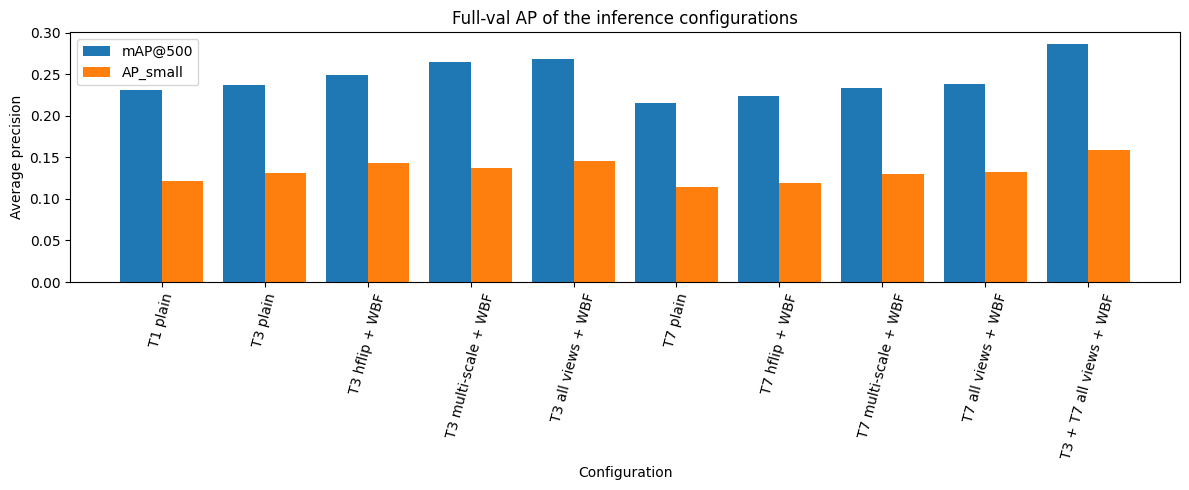

In [35]:
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
positions = np.arange(inference_ablation.height)
ax.bar(positions - 0.2, inference_ablation["mAP"], width=0.4, label="mAP@500")
ax.bar(positions + 0.2, inference_ablation["AP_small"], width=0.4, label="AP_small")
ax.set_xticks(positions, labels=inference_ablation["config"].to_list())
ax.tick_params(axis="x", labelrotation=75)
ax.set_title("Full-val AP of the inference configurations")
ax.set_xlabel("Configuration")
ax.set_ylabel("Average precision")
ax.legend()
save_figure(fig, "inference_ablation", inference_ablation.select("config", "n_views", "mAP", "AP_small"))

The cross-family fusion `FINAL_CONFIG_NAME` (all computed views of T3 and T7, equal weights, the selected WBF IoU threshold) is the output of this run: its detections are written to `val_predictions.json`, and the evaluator of its ablation row is reused for the metrics, the per-class table and the size table, so nothing is evaluated twice. The configuration is fixed before the results of this run are known; the pair T3 and T7 is the best pair of the earlier ensemble run (`SCOPE.md` F58). No other row can replace it as the output of the run.

In [36]:
val_predictions = to_coco_results(final_detections, val_image_id_by_key)
(OUTPUT_DIR / "val_predictions.json").write_text(json.dumps(val_predictions))
val_evaluator = final_evaluator
val_metrics = summarise_metrics(val_evaluator)
print(
    f"{len(val_predictions)} detections | mAP {val_metrics['mAP']:.4f} | {final_milliseconds:.1f} ms/image "
    f"| {len(final_members)} views fused"
)

1423000 detections | mAP 0.2862 | 1720.6 ms/image | 8 views fused


`result.json` writer: the core keys are checked before writing. Keys that do not apply to an inference run (`imgsz`, `epochs_planned`, `epochs_run`, `best_epoch`, `batch`, `lr`) are `null`; `train_hours` is the wall-clock time from the start of the run to this cell (all view inference, selections and COCOeval), and `finished_at` is the time of this cell, so the test fusion below is not included. The metrics and `ms_per_image` are those of the cross-family fusion.

In [37]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without the list and dict entries).

In [38]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": None,
    "epochs_planned": None,
    "epochs_run": None,
    "best_epoch": None,
    "batch": None,
    "lr": None,
    "train_frames": train_frames.height,
    "val_frames": val_frames.height,
    "frame_step": FRAME_STEP,
    "ignore_strategy": IGNORE_STRATEGY,
    **val_metrics,
    "ms_per_image": round(final_milliseconds, 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(compute_elapsed_hours(), 2),
    "gpu_name": gpu_name,
    "gpu_count": GPU_COUNT,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "source_kernels": list(SOURCE_KERNELS),
    "model_labels": list(MODEL_LABELS),
    "final_config": FINAL_CONFIG_NAME,
    "final_views": [f"{label}/{spec.name}" for label, spec in final_members],
    "selected_nms_thresholds": selected_nms_by_label,
    "wbf_confidence_type": WBF_CONFIDENCE_TYPE,
    "wbf_iou_threshold": wbf_iou_threshold,
    "wbf_skip_box_threshold": WBF_SKIP_BOX_THRESHOLD,
    "computed_views": [f"{label}/{name}" for label, name in view_results],
    "skipped_views": skipped_views,
    "skipped_rows": skipped_rows,
    "sahi_gate_ap_small_gain": ap_small_gain,
    "sahi_gate_passed": is_sahi_gate_passed,
    "sahi_projected_hours": round(sahi_projected_hours, 2),
    "sahi_full_run": should_run_sahi,
}
write_result(result)
pl.DataFrame([{key: value for key, value in result.items() if not isinstance(value, list | dict)}])

run,notebook,model,family,variant,parent_run,seed,imgsz,epochs_planned,epochs_run,best_epoch,batch,lr,train_frames,val_frames,frame_step,ignore_strategy,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,speed_protocol,train_hours,gpu_name,gpu_count,started_at,finished_at,final_config,wbf_confidence_type,wbf_iou_threshold,wbf_skip_box_threshold,sahi_gate_ap_small_gain,sahi_gate_passed,sahi_projected_hours,sahi_full_run
str,str,str,str,str,str,i64,null,null,null,null,null,null,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,i64,str,str,str,str,f64,f64,f64,bool,f64,bool
"""pipeline-inference""","""new-notebooks/pipeline-inferen…","""torchvision fasterrcnn_resnet5…","""pipeline""","""tuned""","""faster-rcnn-giou""",42,null,null,null,null,null,null,4868,2846,5,"""per_image_mean_fill""",0.2862,0.285,0.5435,0.2646,0.1589,0.2646,0.4743,0.4931,1720.6,"""per view: torchvision models p…",4.8,"""Tesla T4""",2,"""2026-11-07T12:04:13+00:00""","""2026-11-07T16:52:29+00:00""","""T3 + T7 all views + WBF""","""avg""",0.7,0.001,-0.0106,false,1.53,false


Per-class AP and AP50 on all val frames. How to read this table: one row per class, AP is AP@[.50:.95] at 500 detections per frame, empty when the class has no GT in val.

In [39]:
per_class_ap = build_per_class_ap(val_evaluator)
per_class_ap.write_csv(OUTPUT_DIR / "per_class_ap.csv")
per_class_ap

class_id,class_name,AP,AP50
i64,str,f64,f64
0,"""person""",0.3174,0.7225
1,"""bicycle""",0.288,0.6208
2,"""car""",0.4638,0.7089
3,"""van""",0.2984,0.528
4,"""truck""",0.3548,0.5813
5,"""tricycle""",0.3315,0.6609
6,"""bus""",0.0794,0.1009
7,"""motor""",0.1562,0.4247


Per-clip AP of the cross-family fusion (computed with its ablation row; no new evaluation). How to read this table: one row per val clip; `AP` is AP@[.50:.95] at 500 detections per frame (the headline definition), `AP50` is AP at IoU 0.5, `AP_small` is AP on objects under 32² px, empty when the clip has no GT of that size. Written to `per_clip_ap.csv`.

In [40]:
per_clip_ap = final_per_clip_ap
per_clip_ap.write_csv(OUTPUT_DIR / "per_clip_ap.csv")
per_clip_ap

clip,frames,AP,AP50,AP_small
str,i64,f64,f64,f64
"""uav0000086_00000_v""",464,0.323,0.6645,0.2685
"""uav0000117_02622_v""",349,0.3216,0.6013,0.0565
"""uav0000137_00458_v""",233,0.3748,0.7507,0.0031
"""uav0000182_00000_v""",363,0.2474,0.5367,0.1945
"""uav0000268_05773_v""",978,0.2016,0.3465,0.0706
"""uav0000305_00000_v""",184,0.3331,0.4901,0.0437
"""uav0000339_00001_v""",275,0.318,0.5537,0.1062


AP and recall by object size on all val frames, taken from the full-val evaluator. Buckets are COCO's, in original pixels: small < 32², medium < 96², large otherwise. How to read this table: `objects` counts the non-crowd val GT boxes in the bucket (the `all` row is the total, so rows overlap). `AP` and `AP50` are precision-based at 500 detections per frame. `AR500` is the recall averaged over IoU .50:.95 and `recall50` is the recall at IoU 0.5, both at 500 detections per frame. Written to `size_breakdown.csv`.

In [41]:
def read_eval_array(evaluator: COCOeval, name: str) -> np.ndarray:
    values = evaluator.eval[name]
    if not isinstance(values, np.ndarray):
        raise RuntimeError(f"COCOeval has no {name} array; call accumulate() first")
    return values


def build_size_breakdown(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_eval_array(evaluator, "precision")
    recall = read_eval_array(evaluator, "recall")
    areas = np.concatenate(
        [(targets[:, 2] - targets[:, 0]) * (targets[:, 3] - targets[:, 1]) for targets in val_targets_by_key.values()]
    )
    object_counts = [
        len(areas),
        int((areas < SMALL_AREA).sum()),
        int(((areas >= SMALL_AREA) & (areas < MEDIUM_AREA)).sum()),
        int((areas >= MEDIUM_AREA).sum()),
    ]
    return pl.DataFrame(
        [
            {
                "size": size_name,
                "objects": object_count,
                "AP": average_valid_precision(precision[:, :, :, area_index, -1]),
                "AP50": average_valid_precision(precision[0, :, :, area_index, -1]),
                "AR500": average_valid_precision(recall[:, :, area_index, -1]),
                "recall50": average_valid_precision(recall[0, :, area_index, -1]),
            }
            for area_index, (size_name, object_count) in enumerate(
                zip(["all", "small", "medium", "large"], object_counts, strict=True)
            )
        ],
        schema={
            "size": pl.String,
            "objects": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AR500": pl.Float64,
            "recall50": pl.Float64,
        },
    )


size_breakdown = build_size_breakdown(val_evaluator)
size_breakdown.write_csv(OUTPUT_DIR / "size_breakdown.csv")
size_breakdown

size,objects,AP,AP50,AR500,recall50
str,i64,f64,f64,f64,f64
"""all""",114132,0.2862,0.5435,0.4931,0.8104
"""small""",21910,0.1589,0.3913,0.3437,0.7472
"""medium""",79357,0.2646,0.5324,0.4523,0.7752
"""large""",12865,0.4743,0.7479,0.6638,0.9458


## Submission

Fuse the test detections of the same views with the same settings as the val output, and write `submission.csv`: one row per `test_images.csv` row in that order, 0-based class ids, top-left `x y w h` in original pixels, top 500 by score, empty string for frames without detections.

In [42]:
test_detections_by_key, test_fusion_milliseconds = fuse_views(final_members, "test", wbf_iou_threshold)
submission = write_submission_file(OUTPUT_DIR / "submission.csv", test_detections_by_key)
print(
    f"submission.csv: {submission.height} rows, {(submission['PredictionString'] == '').sum()} empty "
    f"| fusion {test_fusion_milliseconds:.1f} ms/frame"
)

/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.76616           1     0.85325           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.58457           1     0.69482           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.62179           1     0.65623           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py:66: UserWarning: Zero area box skipped: [    0.54915           1     0.65111           1].
  warnings.warn("Zero area box skipped: {}.".format(box_part))
/usr/local/lib/python3.13/dist-packages/ensemble_boxes/ensemble_boxes_wbf.py

submission.csv: 3811 rows, 0 empty | fusion 183.6 ms/frame


Format checks on the file as written to disk, against `test_images.csv` and the fixed columns `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [43]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## References

- Solovyev, Wang, Gabruseva. Weighted boxes fusion: ensembling boxes from different object detection models. arXiv:1910.13302 (WBF, class-wise fusion, confidence rescaling).
- `ensemble-boxes` 1.0.10 (`weighted_boxes_fusion`), MIT licence: https://github.com/ZFTurbo/Weighted-Boxes-Fusion
- Akyon, Altinuc, Temizel. Slicing Aided Hyper Inference and Fine-tuning for Small Object Detection. arXiv:2202.06934 (slicing and merging idea of the SAHI gate). The `sahi` package (MIT licence, https://github.com/obss/sahi) is not used; the slicing and the merge are implemented in this notebook after the paper.
- Singh, Davis. An Analysis of Scale Invariance in Object Detection – SNIP. arXiv:1711.08189 (input scale and object size, motivation of the scale views).
- Ren, He, Girshick, Sun. Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks. arXiv:1506.01497 (two models; second-stage NMS).
- Ultralytics YOLO11 (model T7, trained in `dmnk1304/yolo11s-1280-p2`; loaded and run here with `ultralytics` 8.4.193), AGPL-3.0: https://github.com/ultralytics/ultralytics
- Ultralytics thread-safe inference guide (one model instance per thread, used for the two T7 replicas): https://docs.ultralytics.com/guides/yolo-thread-safe-inference/
- PyTorch CUDA semantics (device context, `torch.cuda.synchronize(device)`, caching allocator and `empty_cache`): https://pytorch.org/docs/stable/notes/cuda.html
- torchvision detection models and `ops.batched_nms`, BSD-3-Clause: https://github.com/pytorch/vision
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- Source runs (kernel sources): T1 `faster-rcnn-small-anchors` (`new-notebooks/faster-rcnn-small-anchors.ipynb`), T3 `faster-rcnn-giou`, T7 `yolo11s-1280-p2`; their reports are in `experiments/` and `EXPERIMENTS.md`.
- Protocol code (split, COCO evaluation, per-clip AP, size breakdown, `result.json`, submission and checks, WBF fusion): copied from `new-notebooks/pipeline-ensemble-wbf.ipynb`; model loading, the prediction functions and the T7 prediction checks follow `new-notebooks/faster-rcnn-small-anchors.ipynb`, `new-notebooks/faster-rcnn-giou.ipynb` and `new-notebooks/yolo11s-1280-p2.ipynb`. No legacy notebook code is used.
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md` (§5: the 4K val clip and the test resolutions; the test-resolution check).
- Planning document `SCOPE.md` (§3 principles, §3.10 decision rule, findings F9, F25, F26, F34, F39, F42, F58, F62) as the source of the motivation numbers in the Overview.